# ANOVA Analizi (veri seti başına) ve Etkileşim Grafikleri

Ana CNN deneyleri (4 veri seti × 30 kombinasyon × 3 seed = 360 koşu) için her veri setinde ayrı iki yönlü ANOVA (aktivasyon × optimizer).

- Ana tablo **Tip III** (sum-to-zero kodlama); Tip II karşılaştırma için verilir. Dengeli veri setlerinde ikisi aynıdır; MNIST'te (bir hücrede n = 2) farklılaşabilir.
- **Tukey** karşılaştırmaları ANOVA modelinin MSE ve artık serbestlik derecesiyle, marjinal ortalamalar üzerinden yapılır.
- Etkileşimin anlamlı olduğu veri setlerinde **basit etki** karşılaştırmaları (her optimizer içinde aktivasyonlar, her aktivasyon içinde optimizer'lar) üretilir.
- **Dayanıklılık kontrolü:** HC3 dayanıklı ANOVA ve artıklar üzerinden permütasyon (etkileşim F) testi.
- p değerleri bilimsel gösterimle verilir.
- Grafiklerde aktivasyon sırası sabittir; MNIST–SGD–ELU hücresi n = 2'dir.

## 1. Kurulum

In [5]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')

DRIVE_PROJE = Path('/content/drive/MyDrive/tez_deney_sonuclari')
DRIVE_ANA = DRIVE_PROJE / 'ana_deney'          # altında cifar10, mnist, animals10, flowers5 var
CIKTI = DRIVE_PROJE / 'anova_ciktilari'
CIKTI.mkdir(exist_ok=True)

# Metrik: 'test_accuracy' ana ölçüt. Gerekirse 'test_macro_f1' ile de tekrarlanabilir.
METRIK = 'test_accuracy'
print('Okunacak dizin:', DRIVE_ANA, '| var mı:', DRIVE_ANA.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Okunacak dizin: /content/drive/MyDrive/tez_deney_sonuclari/ana_deney | var mı: True


## 2. Sonuçları toplama (veri seti klasör adından alınır)

In [6]:
satirlar = []
hatalar = []
for json_yolu in DRIVE_ANA.rglob('tamamlandi.json'):
    try:
        with open(json_yolu, 'r', encoding='utf-8') as f:
            v = json.load(f)
        veri_seti = json_yolu.relative_to(DRIVE_ANA).parts[0]   # cifar10 / mnist / animals10 / flowers5

        # Türkçe ve İngilizce anahtar adları desteklenir
        satirlar.append({
            'dataset': veri_seti,
            'optimizer': v.get('optimizer', v.get('optimizasyon')),
            'activation': v.get('activation', v.get('aktivasyon')),
            'seed': v.get('seed', v.get('tohum')),
            'test_accuracy': v.get('test_accuracy', 0) * 100,
            'test_macro_f1': v.get('test_macro_f1', 0) * 100,
            'yol': str(json_yolu.parent.name),
        })
    except Exception as e:
        hatalar.append((str(json_yolu), repr(e)))

df = pd.DataFrame(satirlar)
print('Bulunan veri seti klasörleri ve koşu sayıları (ham):')
print(df['dataset'].value_counts())

# Sadece 4 ana veri seti; başka klasör/dosya analize girmesin
DATASETLER = ['cifar10', 'mnist', 'animals10', 'flowers5']
df = df[df['dataset'].isin(DATASETLER)].copy()
print(f'Toplam {len(df)} koşu yüklendi, {len(hatalar)} dosya okunamadı.')
for h in hatalar[:5]:
    print('HATA:', h)

# --- Sağlık kontrolleri ---
print('\nVeri seti başına koşu sayısı (beklenen: 90; MNIST 89 olabilir):')
print(df.groupby('dataset').size())
print('\nEksik/NaN değerler:')
print(df[['optimizer', 'activation', 'test_accuracy']].isna().sum())
hucre = df.groupby(['dataset', 'optimizer', 'activation']).size()
print('\nEksik veya fazla hücreler (3 olmayan):')
print(hucre[hucre != 3])
display(df.head())

Bulunan veri seti klasörleri ve koşu sayıları (ham):
dataset
flowers5     90
animals10    90
cifar10      90
mnist        89
Name: count, dtype: int64
Toplam 359 koşu yüklendi, 0 dosya okunamadı.

Veri seti başına koşu sayısı (beklenen: 90; MNIST 89 olabilir):
dataset
animals10    90
cifar10      90
flowers5     90
mnist        89
dtype: int64

Eksik/NaN değerler:
optimizer        0
activation       0
test_accuracy    0
dtype: int64

Eksik veya fazla hücreler (3 olmayan):
dataset  optimizer  activation
mnist    sgd        elu           2
dtype: int64


,dataset,optimizer,activation,seed,test_accuracy,test_macro_f1,yol
0,flowers5,sgd,relu,101,66.898148,66.731946,MAIN-FLOWERS5-SGD-RELU-S101
1,flowers5,sgd,leaky_relu,101,65.972222,65.969669,MAIN-FLOWERS5-SGD-LEAKY_RELU-S101
2,flowers5,sgd,elu,101,68.981481,68.904228,MAIN-FLOWERS5-SGD-ELU-S101
3,flowers5,sgd,gelu,101,68.981481,69.011769,MAIN-FLOWERS5-SGD-GELU-S101
4,flowers5,sgd,swish,101,68.055556,68.236950,MAIN-FLOWERS5-SGD-SWISH-S101


## 3. Yardımcı fonksiyonlar (p biçimi, MSE tabanlı Tukey)

In [7]:
def fp(p):
    """p değerini bilimsel gösterimle biçimlendirir."""
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return 'NaN'
    if p < 1e-3:
        return f'{p:.2e}'
    return f'{p:.3f}'

def tukey_from_means(etiketler, ortalamalar, varyanslar, mse_df, kis=None):
    """Tukey(-Kramer) karşılaştırması: ortalama tahminlerinin varyansları ve ANOVA modelinin residual df'i ile.
    varyanslar[i] = i. ortalama tahmininin varyansı (MSE * ...)."""
    k = len(etiketler)
    qkrit = stats.studentized_range.ppf(0.95, k, mse_df)
    satirlar = []
    for i in range(k):
        for j in range(i + 1, k):
            fark = ortalamalar[i] - ortalamalar[j]
            v = varyanslar[i] + varyanslar[j]
            se = np.sqrt(v / 2)
            q = abs(fark) / se
            p = float(stats.studentized_range.sf(q, k, mse_df))
            satirlar.append({'A': etiketler[i], 'B': etiketler[j], 'fark(A-B)': fark,
                             'ci_alt': fark - qkrit * se, 'ci_ust': fark + qkrit * se,
                             'p_tukey': p, 'p_str': fp(p), 'anlamli': p < 0.05})
    return pd.DataFrame(satirlar)

def marjinal_tukey(d, faktor, diger, mse, df_res):
    """Model tabanlı marjinal ortalamalar (hücre ortalamalarının ortalaması) üzerinden Tukey."""
    hucre = d.groupby([faktor, diger])[METRIK].agg(['mean', 'count']).reset_index()
    et, ort, var = [], [], []
    for sev, g in hucre.groupby(faktor):
        J = len(g)
        et.append(sev)
        ort.append(g['mean'].mean())
        var.append(mse / J**2 * (1.0 / g['count']).sum())
    return tukey_from_means(et, ort, var, df_res)

def basit_etki_tukey(d, sabit, degisen, mse, df_res):
    """Sabit faktörün her düzeyinde, değişen faktörün düzeylerini hücre ortalamalarıyla karşılaştır."""
    cikti = []
    for sev, g in d.groupby(sabit):
        h = g.groupby(degisen)[METRIK].agg(['mean', 'count']).reset_index()
        t = tukey_from_means(list(h[degisen]), list(h['mean']), list(mse / h['count']), df_res)
        t.insert(0, sabit, sev)
        cikti.append(t)
    return pd.concat(cikti, ignore_index=True)

def temiz_ad(s):
    return (s.replace('C(optimizer, Sum)', 'optimizer').replace('C(activation, Sum)', 'activation')
             .replace('C(optimizer)', 'optimizer').replace('C(activation)', 'activation'))

def hesapla_tablo(model, typ):
    t = sm.stats.anova_lm(model, typ=typ)
    t.index = [temiz_ad(i) for i in t.index]
    if 'Intercept' in t.index:
        t = t.drop('Intercept')
    ss_res = t.loc['Residual', 'sum_sq']
    t['partial_eta2'] = t['sum_sq'] / (t['sum_sq'] + ss_res)
    t.loc['Residual', 'partial_eta2'] = np.nan
    return t

## 4. Veri seti başına ANOVA, varsayımlar ve dayanıklılık kontrolü

- Ana tablo: **Tip III** (sum-to-zero). Karşılaştırma için Tip II de hesaplanır.
- Varsayımlar: Levene (hücre bazında) ve Shapiro-Wilk (artıklar).
- Dayanıklılık: HC3 dayanıklı ANOVA (Wald) ve artık permütasyonuyla etkileşim F testi (2000 permütasyon).

In [8]:
rng = np.random.default_rng(2026)
N_PERM = 2000
sonuclar = {}
ozet = []

for ds, d in df.groupby('dataset'):
    d = d.dropna(subset=['optimizer', 'activation', METRIK]).copy()
    n_hucre = d.groupby(['optimizer', 'activation']).ngroups
    print(f'[{ds}] satır={len(d)}, optimizer={d.optimizer.nunique()}, aktivasyon={d.activation.nunique()}, hücre={n_hucre}')
    if len(d) <= n_hucre:
        print(f'  -> ATLANDI: {ds} için hücre başına tekrar yok.')
        continue

    model_t = ols(f'{METRIK} ~ C(optimizer) * C(activation)', data=d).fit()
    model_sum = ols(f'{METRIK} ~ C(optimizer, Sum) * C(activation, Sum)', data=d).fit()
    t2 = hesapla_tablo(model_t, 2)
    t3 = hesapla_tablo(model_sum, 3)
    mse = model_t.mse_resid
    df_res = int(model_t.df_resid)
    sonuclar[ds] = dict(model=model_t, t2=t2, t3=t3, d=d, mse=mse, df_res=df_res)

    # Varsayımlar
    gruplar = [g[METRIK].values for _, g in d.groupby(['optimizer', 'activation'])]
    lev = stats.levene(*gruplar, center='median')
    shp = stats.shapiro(model_t.resid)

    # HC3 dayanıklı ANOVA (etkileşim p)
    p_hc3 = {}
    try:
        rob = sm.stats.anova_lm(model_sum, typ=3, robust='hc3')
        rob.index = [temiz_ad(i) for i in rob.index]
        pcol = [c for c in rob.columns if str(c).startswith('PR(')][0]
        for etki in ['optimizer', 'activation', 'optimizer:activation']:
            p_hc3[etki] = float(rob.loc[etki, pcol])
    except Exception as e:
        print('  HC3 hesaplanamadı:', repr(e)[:120])

    # Permütasyon testi (etkileşim): ana etkili modelin residual'leri permüte edilir
    p_perm = np.nan
    try:
        ana = ols(f'{METRIK} ~ C(optimizer, Sum) + C(activation, Sum)', data=d).fit()
        tam_F = sm.stats.anova_lm(model_sum, typ=3).loc['C(optimizer, Sum):C(activation, Sum)', 'F']
        tahmin, art = ana.fittedvalues.values, ana.resid.values
        say = 0
        for _ in range(N_PERM):
            d2 = d.copy()
            d2[METRIK] = tahmin + rng.permutation(art)
            m = ols(f'{METRIK} ~ C(optimizer, Sum) * C(activation, Sum)', data=d2).fit()
            F = sm.stats.anova_lm(m, typ=3).loc['C(optimizer, Sum):C(activation, Sum)', 'F']
            say += F >= tam_F
        p_perm = (say + 1) / (N_PERM + 1)
    except Exception as e:
        print('  Permütasyon hesaplanamadı:', repr(e)[:120])

    print(f'\n================ {ds}  (n={len(d)}, residual df={df_res}) — TİP III ================')
    goster = t3.copy()
    goster['p'] = goster['PR(>F)'].map(fp)
    display(goster[['sum_sq', 'df', 'F', 'p', 'partial_eta2']].round(4))
    print('Tip II p değerleri:', {k: fp(v) for k, v in t2['PR(>F)'].dropna().items()})
    print('HC3 p değerleri   :', {k: fp(v) for k, v in p_hc3.items()})
    print(f'Permütasyon (etkileşim) p = {fp(p_perm)}')
    print(f'Levene p = {fp(lev.pvalue)} | Shapiro-Wilk (residual) p = {fp(shp.pvalue)}',
          '<-- normallik reddedildi, dayanıklılık kontrolünü raporla' if shp.pvalue < 0.05 else '')

    for etki in ['optimizer', 'activation', 'optimizer:activation']:
        satir = t3.loc[etki]
        ozet.append({'dataset': ds, 'etki': etki, 'n': len(d), 'residual_df': df_res,
                     'F_tip3': satir['F'], 'p_tip3': satir['PR(>F)'], 'p_tip3_str': fp(satir['PR(>F)']),
                     'partial_eta2': satir['partial_eta2'],
                     'p_tip2_str': fp(t2.loc[etki, 'PR(>F)']),
                     'p_hc3_str': fp(p_hc3.get(etki, np.nan)),
                     'p_perm_etkilesim_str': fp(p_perm) if etki == 'optimizer:activation' else '',
                     'levene_p_str': fp(lev.pvalue), 'shapiro_p_str': fp(shp.pvalue)})

ozet_df = pd.DataFrame(ozet)
from statsmodels.stats.multitest import multipletests
ozet_df['p_holm'] = multipletests(ozet_df['p_tip3'], method='holm')[1]
ozet_df['p_holm_str'] = ozet_df['p_holm'].map(fp)
ozet_df.to_csv(CIKTI / 'anova_ozet_tum_veri_setleri_v2.csv', index=False)
print('\n=== ÖZET (12 test, Holm düzeltmeli) ===')
display(ozet_df[['dataset', 'etki', 'n', 'F_tip3', 'p_tip3_str', 'p_holm_str', 'partial_eta2', 'p_tip2_str', 'p_hc3_str', 'p_perm_etkilesim_str']].round(3))

[animals10] satır=90, optimizer=5, aktivasyon=6, hücre=30

================ animals10  (n=90, residual df=60) — TİP III ================


,sum_sq,df,F,p,partial_eta2
optimizer,102.8279,4.0,44.3341,2.84e-17,0.7472
activation,18.6843,5.0,6.4446,7.44e-05,0.3494
optimizer:activation,32.6055,20.0,2.8116,0.001,0.4838
Residual,34.7908,60.0,NaN,NaN,NaN


Tip II p değerleri: {'optimizer': '2.84e-17', 'activation': '7.44e-05', 'optimizer:activation': '0.001'}
HC3 p değerleri   : {'optimizer': '1.70e-12', 'activation': '0.004', 'optimizer:activation': '1.34e-08'}
Permütasyon (etkileşim) p = 0.001
Levene p = 0.988 | Shapiro-Wilk (residual) p = 0.905 
[cifar10] satır=90, optimizer=5, aktivasyon=6, hücre=30

================ cifar10  (n=90, residual df=60) — TİP III ================


,sum_sq,df,F,p,partial_eta2
optimizer,8.8607,4.0,12.0515,2.98e-07,0.4455
activation,27.2996,5.0,29.7043,4.74e-15,0.7123
optimizer:activation,6.1547,20.0,1.6742,0.064,0.3582
Residual,11.0285,60.0,NaN,NaN,NaN


Tip II p değerleri: {'optimizer': '2.98e-07', 'activation': '4.74e-15', 'optimizer:activation': '0.064'}
HC3 p değerleri   : {'optimizer': '7.90e-05', 'activation': '1.15e-11', 'optimizer:activation': '0.005'}
Permütasyon (etkileşim) p = 0.061
Levene p = 0.982 | Shapiro-Wilk (residual) p = 0.680 
[flowers5] satır=90, optimizer=5, aktivasyon=6, hücre=30

================ flowers5  (n=90, residual df=60) — TİP III ================


,sum_sq,df,F,p,partial_eta2
optimizer,349.4406,4.0,35.5713,3.24e-15,0.7034
activation,16.1424,5.0,1.3146,0.270,0.0987
optimizer:activation,56.9666,20.0,1.1598,0.320,0.2788
Residual,147.3551,60.0,NaN,NaN,NaN


Tip II p değerleri: {'optimizer': '3.24e-15', 'activation': '0.270', 'optimizer:activation': '0.320'}
HC3 p değerleri   : {'optimizer': '9.41e-12', 'activation': '0.485', 'optimizer:activation': '0.098'}
Permütasyon (etkileşim) p = 0.315
Levene p = 0.999 | Shapiro-Wilk (residual) p = 0.213 
[mnist] satır=89, optimizer=5, aktivasyon=6, hücre=30

================ mnist  (n=89, residual df=59) — TİP III ================


,sum_sq,df,F,p,partial_eta2
optimizer,0.2349,4.0,9.5276,5.19e-06,0.3924
activation,0.1955,5.0,6.3417,8.95e-05,0.3496
optimizer:activation,0.1728,20.0,1.4016,0.158,0.3221
Residual,0.3637,59.0,NaN,NaN,NaN


Tip II p değerleri: {'optimizer': '1.02e-05', 'activation': '2.23e-05', 'optimizer:activation': '0.158'}
HC3 p değerleri   : {'optimizer': '1.12e-04', 'activation': '0.021', 'optimizer:activation': '0.264'}
Permütasyon (etkileşim) p = 0.168
Levene p = 1.000 | Shapiro-Wilk (residual) p = 0.034 <-- normallik reddedildi, dayanıklılık kontrolünü raporla

=== ÖZET (12 test, Holm düzeltmeli) ===


,dataset,etki,n,F_tip3,p_tip3_str,p_holm_str,partial_eta2,p_tip2_str,p_hc3_str,p_perm_etkilesim_str
0,animals10,optimizer,90,44.334,2.84e-17,3.41e-16,0.747,2.84e-17,1.70e-12,
1,animals10,activation,90,6.445,7.44e-05,5.21e-04,0.349,7.44e-05,0.004,
2,animals10,optimizer:activation,90,2.812,0.001,0.005,0.484,0.001,1.34e-08,0.001
3,cifar10,optimizer,90,12.052,2.98e-07,2.68e-06,0.446,2.98e-07,7.90e-05,
4,cifar10,activation,90,29.704,4.74e-15,4.74e-14,0.712,4.74e-15,1.15e-11,
5,cifar10,optimizer:activation,90,1.674,0.064,0.258,0.358,0.064,0.005,0.061
6,flowers5,optimizer,90,35.571,3.24e-15,3.56e-14,0.703,3.24e-15,9.41e-12,
7,flowers5,activation,90,1.315,0.270,0.540,0.099,0.270,0.485,
8,flowers5,optimizer:activation,90,1.160,0.320,0.540,0.279,0.320,0.098,0.315
9,mnist,optimizer,89,9.528,5.19e-06,4.15e-05,0.392,1.02e-05,1.12e-04,


## 5. Post-hoc: model tabanlı Tukey (ANOVA MSE'si ile) ve basit etkiler

- Marjinal Tukey: hata terimi ANOVA modelinin MSE'sidir.
- Etkileşimin anlamlı olduğu veri setlerinde (Tip III p < 0,05) her optimizer içinde aktivasyonlar ve her aktivasyon içinde optimizer'lar için basit etki karşılaştırmaları da üretilir.

In [9]:
for ds, s in sonuclar.items():
    d, mse, df_res = s['d'], s['mse'], s['df_res']
    p_et = s['t3'].loc['optimizer:activation', 'PR(>F)']
    for faktor, diger in [('optimizer', 'activation'), ('activation', 'optimizer')]:
        mt = marjinal_tukey(d, faktor, diger, mse, df_res)
        mt.to_csv(CIKTI / f'tukey_marjinal_{ds}_{faktor}.csv', index=False)
        print(f'\n--- {ds} | marjinal Tukey ({faktor}; ANOVA MSE) — anlamlı çift sayısı: {int(mt.anlamli.sum())}/{len(mt)} ---')
        display(mt[mt.anlamli][['A', 'B', 'fark(A-B)', 'ci_alt', 'ci_ust', 'p_str']].round(3))
    if p_et < 0.05:
        print(f'\n>>> {ds}: ETKİLEŞİM ANLAMLI (p={fp(p_et)}). Basit etkiler üretiliyor.')
        for sabit, degisen in [('optimizer', 'activation'), ('activation', 'optimizer')]:
            se = basit_etki_tukey(d, sabit, degisen, mse, df_res)
            se.to_csv(CIKTI / f'basit_etki_{ds}_{sabit}_icinde_{degisen}.csv', index=False)
            print(f'  {sabit} sabit, {degisen} değişken: anlamlı çift {int(se.anlamli.sum())}/{len(se)}')
            display(se[se.anlamli][[sabit, 'A', 'B', 'fark(A-B)', 'p_str']].round(3).head(30))


--- animals10 | marjinal Tukey (optimizer; ANOVA MSE) — anlamlı çift sayısı: 6/10 ---


,A,B,fark(A-B),ci_alt,ci_ust,p_str
1,adam,momentum_sgd,1.256,0.542,1.970,6.10e-05
3,adam,sgd,2.922,2.208,3.636,3.33e-15
4,adamw,momentum_sgd,1.182,0.468,1.896,1.73e-04
6,adamw,sgd,2.848,2.134,3.562,4.88e-15
8,momentum_sgd,sgd,1.666,0.952,2.380,1.37e-07
9,rmsprop,sgd,2.232,1.519,2.946,2.18e-11



--- animals10 | marjinal Tukey (activation; ANOVA MSE) — anlamlı çift sayısı: 5/15 ---


,A,B,fark(A-B),ci_alt,ci_ust,p_str
3,elu,relu,1.013,0.195,1.832,0.007
7,gelu,relu,0.927,0.108,1.745,0.018
9,leaky_relu,mish,-0.955,-1.773,-0.136,0.013
12,mish,relu,1.464,0.646,2.283,2.85e-05
13,mish,swish,0.835,0.017,1.654,0.043



>>> animals10: ETKİLEŞİM ANLAMLI (p=0.001). Basit etkiler üretiliyor.
  optimizer sabit, activation değişken: anlamlı çift 11/75


,optimizer,A,B,fark(A-B),p_str
30,momentum_sgd,elu,gelu,1.897,0.038
33,momentum_sgd,elu,relu,2.063,0.018
34,momentum_sgd,elu,swish,2.534,0.002
52,rmsprop,gelu,relu,1.859,0.044
54,rmsprop,leaky_relu,mish,-1.986,0.026
57,rmsprop,mish,relu,2.355,0.005
60,sgd,elu,gelu,1.974,0.027
61,sgd,elu,leaky_relu,2.330,0.005
63,sgd,elu,relu,2.890,2.63e-04
64,sgd,elu,swish,2.190,0.010


... (10 outputs left out)


--- mnist | marjinal Tukey (optimizer; ANOVA MSE) — anlamlı çift sayısı: 6/10 ---


,A,B,fark(A-B),ci_alt,ci_ust,p_str
1,adam,momentum_sgd,-0.115,-0.189,-0.041,4.39e-04
3,adam,sgd,-0.127,-0.202,-0.052,1.31e-04
4,adamw,momentum_sgd,-0.092,-0.166,-0.019,0.007
6,adamw,sgd,-0.104,-0.179,-0.029,0.002
7,momentum_sgd,rmsprop,0.086,0.012,0.160,0.014
9,rmsprop,sgd,-0.098,-0.173,-0.023,0.005



--- mnist | marjinal Tukey (activation; ANOVA MSE) — anlamlı çift sayısı: 5/15 ---


,A,B,fark(A-B),ci_alt,ci_ust,p_str
0,elu,gelu,-0.148,-0.235,-0.061,6.76e-05
1,elu,leaky_relu,-0.116,-0.203,-0.029,0.003
2,elu,mish,-0.118,-0.205,-0.031,0.002
3,elu,relu,-0.133,-0.220,-0.047,3.94e-04
4,elu,swish,-0.114,-0.201,-0.027,0.003


## 6. Etkileşim grafikleri (aktivasyon sırası sabit; ± SD)

Kaydedildi: /content/drive/MyDrive/tez_deney_sonuclari/anova_ciktilari/ANOVA_Etkilesim_Grafikleri_v2.png


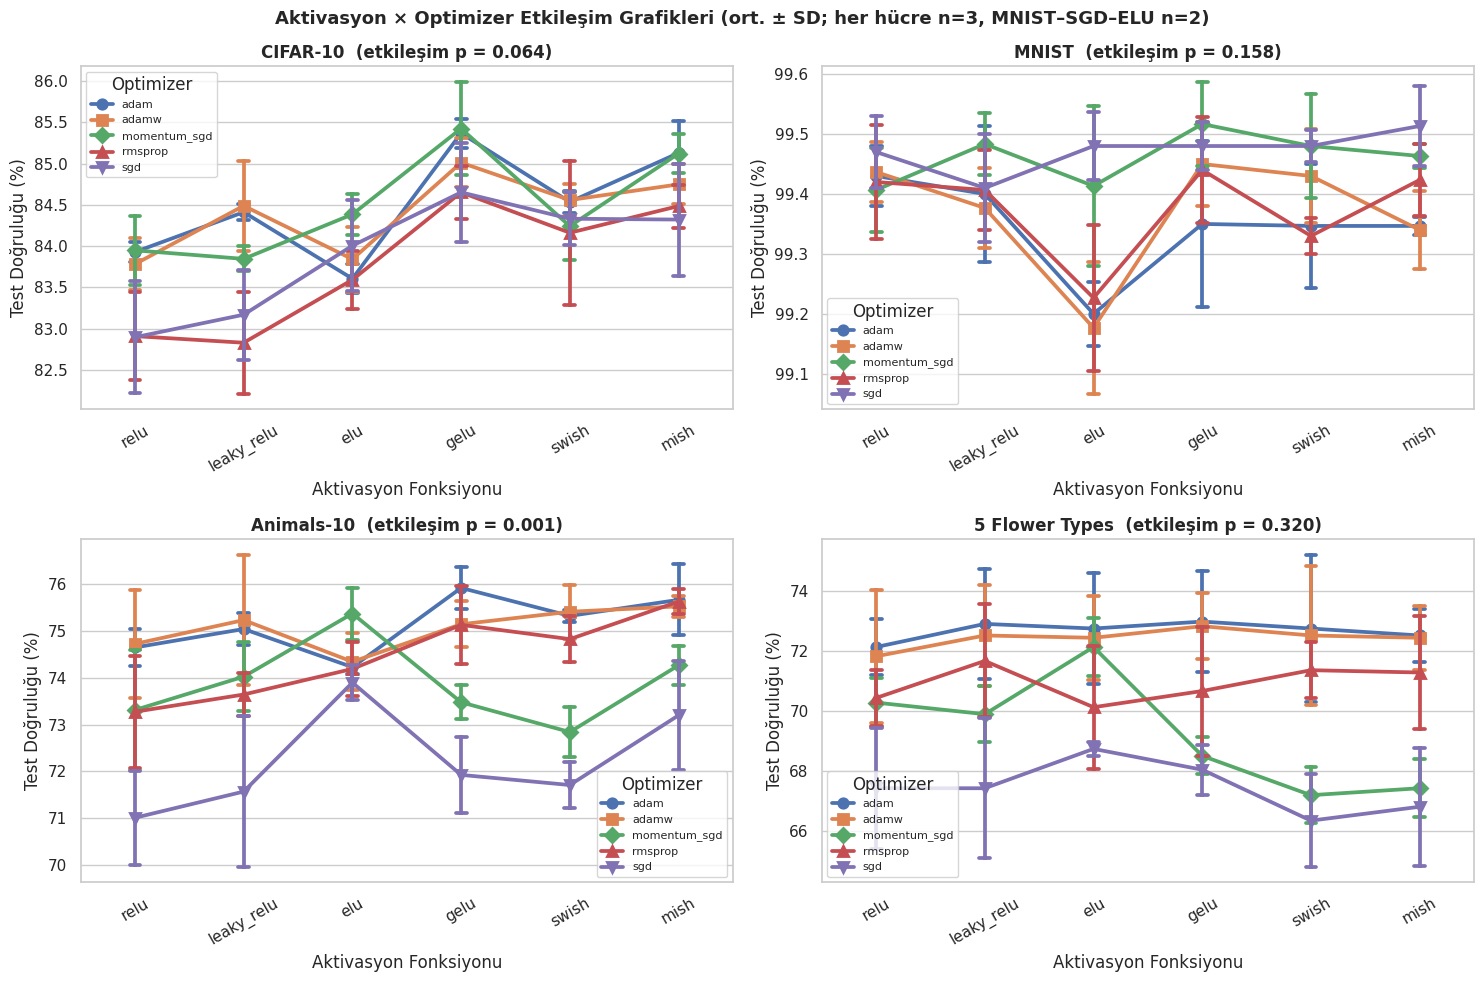

In [10]:
sns.set_theme(style='whitegrid')
adlar = {'cifar10': 'CIFAR-10', 'mnist': 'MNIST', 'animals10': 'Animals-10', 'flowers5': '5 Flower Types'}
ETKI_SIRA = ['relu', 'leaky_relu', 'elu', 'gelu', 'swish', 'mish']   # tüm panellerde aynı
sira = [k for k in DATASETLER if k in sonuclar]
opt_sira = sorted(df['optimizer'].dropna().unique())

fig, eksenler = plt.subplots(2, 2, figsize=(15, 10), squeeze=False)
for ax, ds in zip(eksenler.ravel(), sira):
    d = sonuclar[ds]['d']
    act_sira = [a for a in ETKI_SIRA if a in set(d['activation'])] or sorted(d['activation'].unique())
    sns.pointplot(data=d, x='activation', y=METRIK, hue='optimizer', order=act_sira, hue_order=opt_sira,
                  errorbar='sd', capsize=.1, markers=['o', 's', 'D', '^', 'v'][:len(opt_sira)], ax=ax)
    p_et = sonuclar[ds]['t3'].loc['optimizer:activation', 'PR(>F)']
    baslik = adlar.get(ds, ds) + f'  (etkileşim p = {fp(p_et)})'
    ax.set_title(baslik, fontweight='bold')
    ax.set_xlabel('Aktivasyon Fonksiyonu')
    ax.set_ylabel('Test Doğruluğu (%)')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(title='Optimizer', fontsize=8)
fig.suptitle('Aktivasyon × Optimizer Etkileşim Grafikleri (ort. ± SD; her hücre n=3, MNIST–SGD–ELU n=2)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
yol = CIKTI / 'ANOVA_Etkilesim_Grafikleri_v2.png'
plt.savefig(yol, dpi=300, bbox_inches='tight')
print('Kaydedildi:', yol)
plt.show()